In [ ]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split, GroupShuffleSplit

import warnings as wr
wr.filterwarnings('ignore')

np.random.seed(1)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Read Test Ground Truth CSV File

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ML Project/HAM10000_metadata.csv")
print(df)
print(df.shape)

         lesion_id      image_id     dx dx_type   age     sex localization
0      HAM_0000118  ISIC_0027419    bkl   histo  80.0    male        scalp
1      HAM_0000118  ISIC_0025030    bkl   histo  80.0    male        scalp
2      HAM_0002730  ISIC_0026769    bkl   histo  80.0    male        scalp
3      HAM_0002730  ISIC_0025661    bkl   histo  80.0    male        scalp
4      HAM_0001466  ISIC_0031633    bkl   histo  75.0    male          ear
...            ...           ...    ...     ...   ...     ...          ...
10010  HAM_0002867  ISIC_0033084  akiec   histo  40.0    male      abdomen
10011  HAM_0002867  ISIC_0033550  akiec   histo  40.0    male      abdomen
10012  HAM_0002867  ISIC_0033536  akiec   histo  40.0    male      abdomen
10013  HAM_0000239  ISIC_0032854  akiec   histo  80.0    male         face
10014  HAM_0003521  ISIC_0032258    mel   histo  70.0  female         back

[10015 rows x 7 columns]
(10015, 7)


In [ ]:
df.describe()

,age
count,9958.000000
mean,51.863828
std,16.968614
min,0.000000
25%,40.000000
50%,50.000000
75%,65.000000
max,85.000000


# Clean the Dataset

In [ ]:
missing = df.isna().sum()
print(missing)

lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


In [ ]:
df[df.isna().any(axis=1)]

,lesion_id,image_id,dx,dx_type,age,sex,localization
968,HAM_0001186,ISIC_0033391,bkl,consensus,NaN,unknown,unknown
969,HAM_0002660,ISIC_0033750,bkl,consensus,NaN,unknown,unknown
970,HAM_0000372,ISIC_0033685,bkl,consensus,NaN,unknown,unknown
971,HAM_0000948,ISIC_0033631,bkl,consensus,NaN,unknown,unknown
972,HAM_0000983,ISIC_0033490,bkl,consensus,NaN,unknown,unknown
973,HAM_0007281,ISIC_0034283,bkl,consensus,NaN,unknown,unknown
974,HAM_0001561,ISIC_0032740,bkl,consensus,NaN,unknown,unknown
975,HAM_0000825,ISIC_0034186,bkl,consensus,NaN,unknown,unknown
977,HAM_0006074,ISIC_0034252,bkl,consensus,NaN,unknown,unknown
978,HAM_0006074,ISIC_0033829,bkl,consensus,NaN,unknown,unknown


In [ ]:
df = df.dropna(subset=["age"]).reset_index(drop=True)

# Visualizing the Data

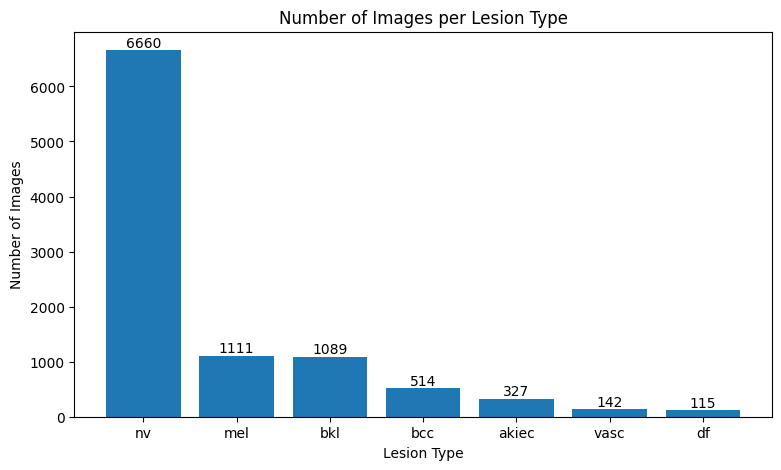

In [ ]:
counts = df["dx"].value_counts()

plt.figure(figsize=(9, 5))
bars = plt.bar(counts.index, counts.values)
plt.bar_label(bars)

plt.title("Number of Images per Lesion Type")
plt.ylabel("Number of Images")
plt.xlabel("Lesion Type")

plt.show()

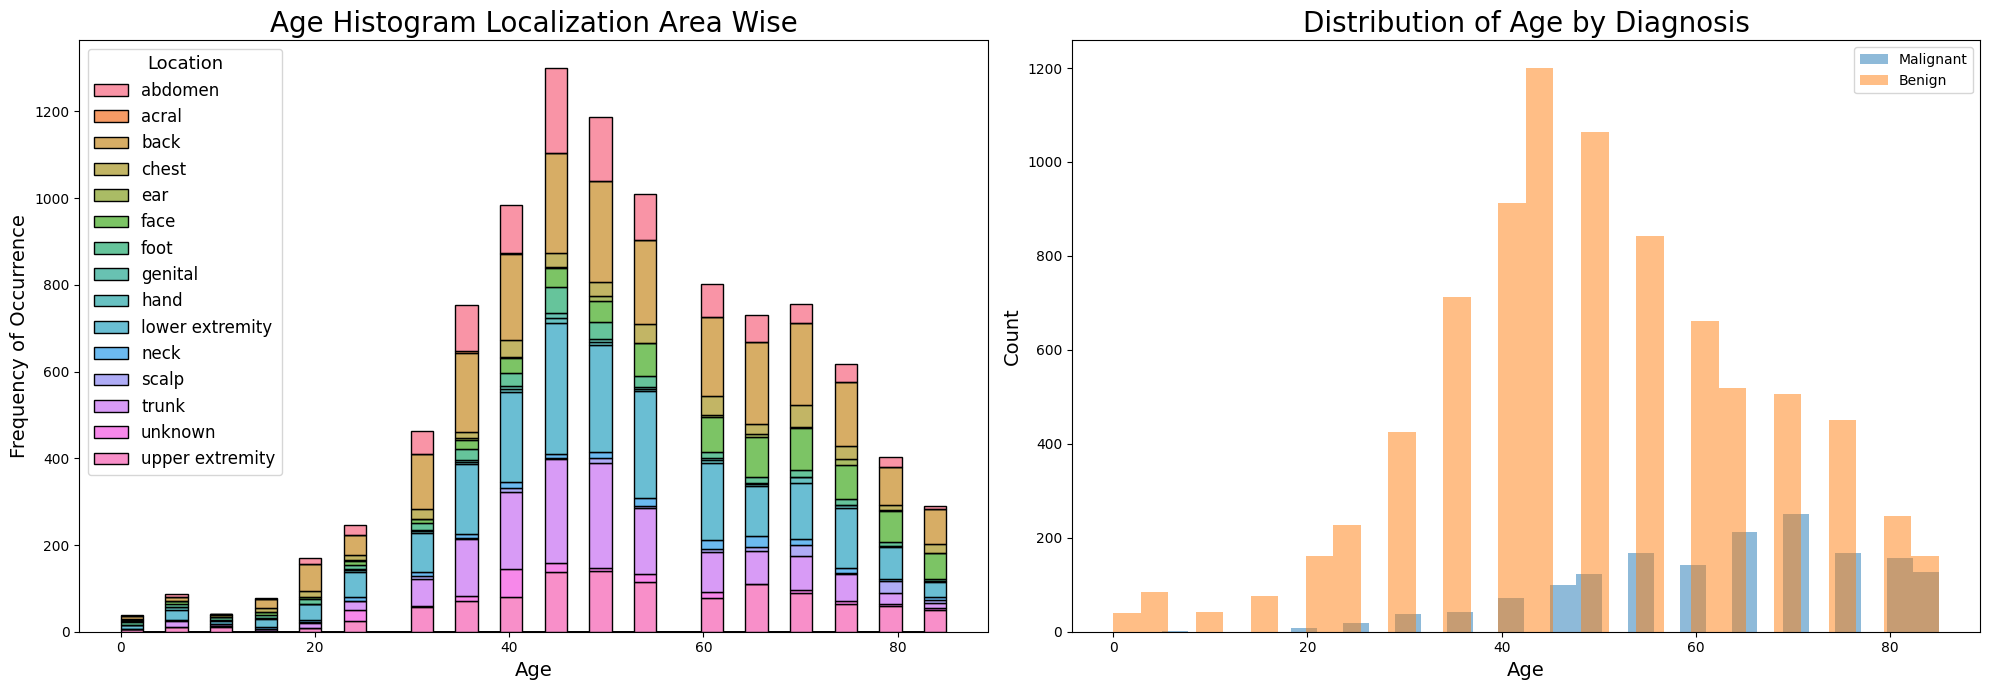

In [ ]:
malignant_types = ["mel", "bcc"]
malignant = df[df["dx"].isin(malignant_types)]
benign = df[~df["dx"].isin(malignant_types)]

fig, ax = plt.subplots(1, 2, figsize=(20, 7))

locations = sorted(df['localization'].dropna().unique())

sns.histplot(data=df, x='age', hue='localization', hue_order=locations, multiple='stack', ax=ax[0])
sns.move_legend(ax[0], loc='upper left', title='Location', title_fontsize=13, fontsize=12)
ax[0].set_title('Age Histogram Localization Area Wise', fontsize=20)
ax[0].set_xlabel('Age', fontsize=14)
ax[0].set_ylabel('Frequency of Occurrence', fontsize=14)

ax[1].hist(malignant["age"].dropna(), bins=30, label="Malignant", alpha=0.5)
ax[1].hist(benign["age"].dropna(), bins=30, label="Benign", alpha=0.5)
ax[1].set_title('Distribution of Age by Diagnosis', fontsize=20)
ax[1].set_xlabel('Age', fontsize=14)
ax[1].set_ylabel('Count', fontsize=14)
ax[1].legend()

plt.tight_layout()
plt.show()


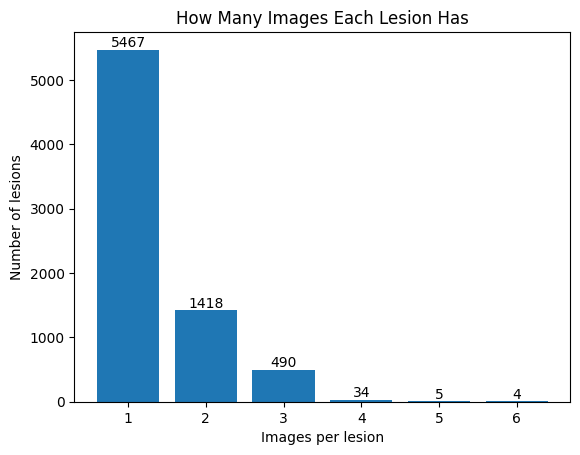

In [ ]:
per_lesion = df.groupby("lesion_id").size().value_counts().sort_index()

bars = plt.bar(per_lesion.index.astype(str), per_lesion.values)
plt.bar_label(bars)
plt.title("How Many Images Each Lesion Has")
plt.xlabel("Images per lesion")
plt.ylabel("Number of lesions")
plt.show()

<Figure size 2000x500 with 0 Axes>

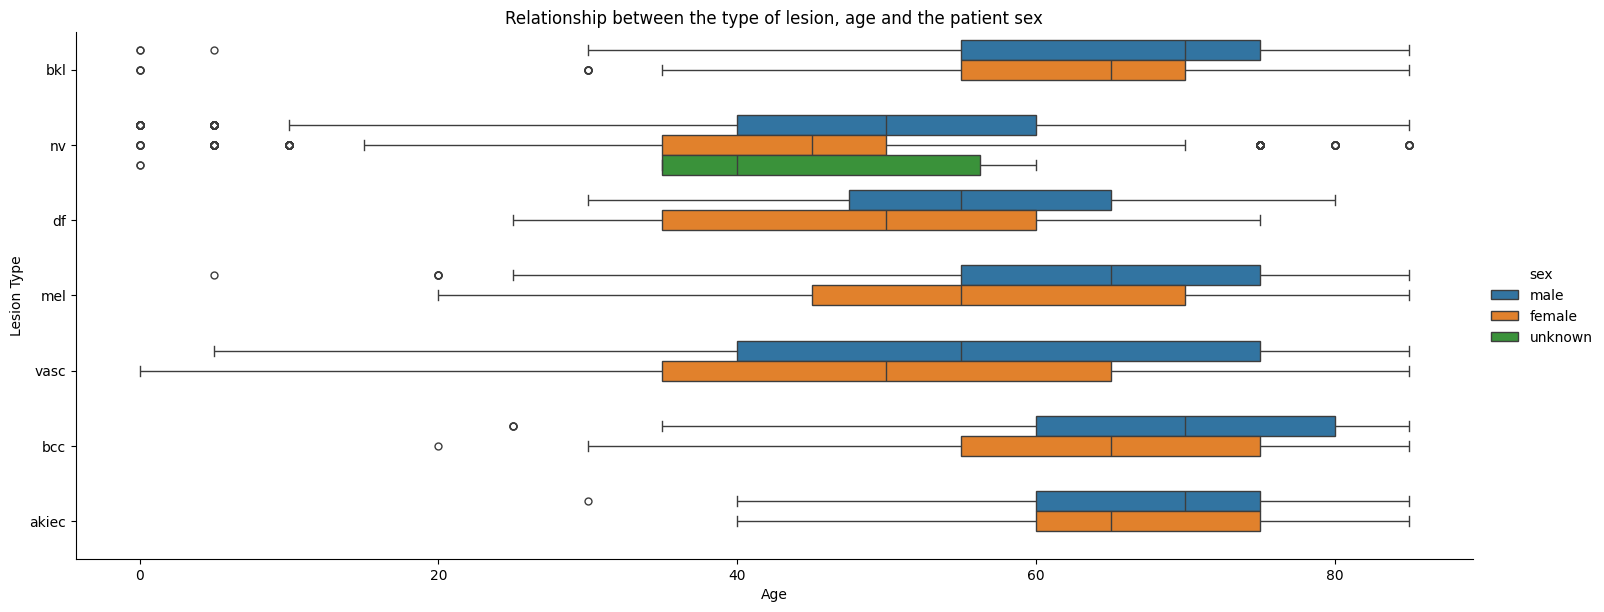

In [ ]:
plt.figure(figsize=(20,5))
sns.catplot(y="dx", x="age", hue="sex",kind="box", height = 6, aspect = 2.5,  data=df).set(title='Relationship between the type of lesion, age and the patient sex')
plt.ylabel('Lesion Type')
plt.xlabel('Age')
plt.show()

# Pre-process the data

In [ ]:
names = ['Melanocytic nevi','Melanoma','Benign keratosis-like lesions ',
               'Basal cell carcinoma','Actinic keratoses','Vascular lesions',
               'Dermatofibroma']

lesion_img = df.groupby('lesion_id')['image_id']\
               .count()\
               .to_frame()

lesion_dict = {
    'nv':'Melanocytic Nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign keratosis',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses',
    'vasc': 'Vascular lesions',
    'df': 'Dermatofibroma'

}

lesion_ID = {
    'nv': 0,
    'mel': 1,
    'bkl': 2,
    'bcc': 3,
    'akiec': 4,
    'vasc': 5,
    'df': 6
}

df['cell_type'] = df['dx'].map(lesion_dict.get)
df['lesion_ID'] = df['dx'].map(lesion_ID.get)

In [ ]:
path = '/content/drive/MyDrive/HAM10000_images'

In [ ]:
images_path = {os.path.splitext(os.path.basename(x))[0]:
               x for x in glob.glob('/content/drive/MyDrive/HAM10000_images/*.jpg')}

In [ ]:
df['path'] = df['image_id'].map(images_path.get)

In [ ]:
df

,lesion_id,image_id,dx,dx_type,age,sex,localization,cell_type,lesion_ID,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,Benign keratosis,2,/content/drive/MyDrive/HAM10000_images/ISIC_00...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,Benign keratosis,2,/content/drive/MyDrive/HAM10000_images/ISIC_00...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,Benign keratosis,2,/content/drive/MyDrive/HAM10000_images/ISIC_00...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,Benign keratosis,2,/content/drive/MyDrive/HAM10000_images/ISIC_00...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,Benign keratosis,2,/content/drive/MyDrive/HAM10000_images/ISIC_00...
...,...,...,...,...,...,...,...,...,...,...
9953,HAM_0002867,ISIC_0033084,akiec,histo,40.0,male,abdomen,Actinic keratoses,4,/content/drive/MyDrive/HAM10000_images/ISIC_00...
9954,HAM_0002867,ISIC_0033550,akiec,histo,40.0,male,abdomen,Actinic keratoses,4,/content/drive/MyDrive/HAM10000_images/ISIC_00...
9955,HAM_0002867,ISIC_0033536,akiec,histo,40.0,male,abdomen,Actinic keratoses,4,/content/drive/MyDrive/HAM10000_images/ISIC_00...
9956,HAM_0000239,ISIC_0032854,akiec,histo,80.0,male,face,Actinic keratoses,4,/content/drive/MyDrive/HAM10000_images/ISIC_00...


In [ ]:
df["path"].head()

,path
0,/content/drive/MyDrive/HAM10000_images/ISIC_00...
1,/content/drive/MyDrive/HAM10000_images/ISIC_00...
2,/content/drive/MyDrive/HAM10000_images/ISIC_00...
3,/content/drive/MyDrive/HAM10000_images/ISIC_00...
4,/content/drive/MyDrive/HAM10000_images/ISIC_00...


In [ ]:
num_unique_id = df["image_id"].nunique()
num_unique_id

9958

In [ ]:
IMG_SIZE = 224

def get_img(img_path):
  img = cv2.imread(img_path,1)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  img = cv2.resize(img,(IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
  return img


In [ ]:
from tqdm import tqdm

x = []
for img_name in tqdm(df['path'].values):
  x.append(get_img(img_name))

100%|██████████| 9958/9958 [14:13<00:00, 11.67it/s]


In [ ]:
x = np.array(x)/255
print(x.shape)

In [ ]:
y = df["lesion_ID"].values

print("x:", x.shape, x.dtype)
print("y:", y.shape, y.dtype)

In [ ]:
groups = df["lesion_id"].values      # which physical lesion each image came from

print("x:", x.shape, x.dtype)
print("y:", y.shape, y.dtype)
print("groups:", groups.shape, "|", len(np.unique(groups)), "unique lesions")

In [ ]:
from numpy.core.function_base import linspace

idx = np.random.choice(len(x), 7, replace=False)
plt.figure(figsize=(20, 4))
for slot, i in enumerate(idx):
    plt.subplot(1, 7, slot + 1)
    plt.imshow(x[i])
    plt.title(df["dx"].iloc[i])
    plt.axis("off")
plt.tight_layout(); plt.show()

# Pre-processing Stage

In [ ]:
# We split LESIONS (moles), not images. Many lesions have several photos. If photos of the
# same lesion land in both train and test, the model is graded on lesions it already saw.

# Step 1: one row per lesion, with its diagnosis (every lesion has exactly one)
lesions = df.drop_duplicates("lesion_id")[["lesion_id", "lesion_ID"]]

# Step 2: split the LESIONS 80% train / 10% validation / 10% test.
# stratify keeps the mix of diagnoses similar in every part.
train_les, rest_les = train_test_split(lesions, test_size=0.20, random_state=28, stratify=lesions["lesion_ID"])
val_les, test_les = train_test_split(rest_les, test_size=0.50, random_state=28, stratify=rest_les["lesion_ID"])

# Step 3: every image goes to the same split as its lesion.
# is_train is a True/False value per image; x[is_train] keeps only the True rows.
is_train = df["lesion_id"].isin(train_les["lesion_id"]).values
is_val = df["lesion_id"].isin(val_les["lesion_id"]).values
is_test = df["lesion_id"].isin(test_les["lesion_id"]).values

x_train, y_train = x[is_train], y[is_train]
x_val, y_val = x[is_val], y[is_val]
x_test, y_test = x[is_test], y[is_test]

In [ ]:
print(x_train.shape)
print(x_val.shape)
print(x_test.shape)
print(y_train.shape)
print(y_val.shape)
print(y_test.shape)

# Transfer Learning

In [ ]:
!pip install -q timm

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix)
import timm

torch.manual_seed(1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# The Model



In [ ]:
class HAM10000Xception(nn.Module):
    def __init__(self, num_classes=7, pretrained=True):
        super(HAM10000Xception, self).__init__()
        self.base_model = timm.create_model('xception', pretrained=pretrained)

        # Replace the final linear layer with a small head for our 7 classes
        in_features = self.base_model.fc.in_features
        self.base_model.fc = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.base_model(x)


model = HAM10000Xception(num_classes=7, pretrained=True).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

# Data


In [ ]:
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(180),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

val_tf = transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])


class SkinDataset(Dataset):
    def __init__(self, x, y, tf=None):
        self.x, self.y, self.tf = x, y, tf

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        # (H, W, C) uint8  ->  (C, H, W) float in 0-1
        img = torch.from_numpy(self.x[i]).permute(2, 0, 1).float().div(255)
        if self.tf is not None:
            img = self.tf(img)
        return img, int(self.y[i])


BATCH_SIZE = 32        # 224px tensors are 10x bigger than 71px ones

train_loader = DataLoader(SkinDataset(x_train, y_train, train_tf), BATCH_SIZE,
                          shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(SkinDataset(x_val, y_val, val_tf), 64, num_workers=2)
test_loader = DataLoader(SkinDataset(x_test, y_test, val_tf), 64, num_workers=2)

print(f"{len(train_loader)} training batches of {BATCH_SIZE}")

# Adjusting Weights

In [ ]:
counts = np.bincount(y_train, minlength=7)

weights = np.sqrt(len(y_train) / (7 * np.maximum(counts, 1)))
weights = weights / weights.mean()
class_weights = torch.tensor(weights, dtype=torch.float)

for i in range(7):
    print(f"{names[i]:<32}{counts[i]:>5} images   weight {weights[i]:.2f}")
print(f"spread: {weights.max()/weights.min():.1f}x")

# Train the Model

In [ ]:
def train_and_validate(model, train_loader, val_loader, num_epochs=12,
                       learning_rate=1e-4, class_weights=None):
    if class_weights is not None:
        class_weights = class_weights.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)

    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    # CHANGE 4: cosine schedule. In the reference run the best epoch came late,
    # as the learning rate decayed.
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

    best_val_bacc = 0.0            # CHANGE 2: balanced accuracy, not accuracy
    history = []

    for epoch in range(num_epochs):
        # ---------------- training ----------------
        model.train()
        running_loss, total = 0.0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()              # 1. clear last batch's gradients
            outputs = model(images)            # 2. forward
            loss = criterion(outputs, labels)  # 3. how wrong
            loss.backward()                    # 4. gradients
            optimizer.step()                   # 5. update

            running_loss += loss.item() * images.size(0)
            total += labels.size(0)

        scheduler.step()
        train_loss = running_loss / total

        # ---------------- validation ----------------
        model.eval()
        val_loss, preds, trues = 0.0, [], []
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                val_loss += criterion(outputs, labels).item() * images.size(0)
                preds.append(outputs.argmax(1).cpu())
                trues.append(labels.cpu())

        preds = torch.cat(preds).numpy()
        trues = torch.cat(trues).numpy()
        val_loss /= len(trues)
        val_acc = accuracy_score(trues, preds)
        val_bacc = balanced_accuracy_score(trues, preds)
        history.append({"epoch": epoch+1, "train_loss": train_loss, "val_loss": val_loss,
                        "val_acc": val_acc, "val_bacc": val_bacc})

        flag = ""
        if val_bacc > best_val_bacc:
            best_val_bacc = val_bacc
            torch.save(model.state_dict(), "best_xception_ham10000.pth")
            flag = "  <- best, saved"

        print(f"epoch {epoch+1:>2}/{num_epochs} | train loss {train_loss:.4f} | "
              f"val loss {val_loss:.4f} | acc {val_acc:.4f} | "
              f"balanced acc {val_bacc:.4f}{flag}")

    # CHANGE 5: the model in memory still holds the LAST epoch. Load the best one back.
    model.load_state_dict(torch.load("best_xception_ham10000.pth"))
    print(f"\nbest validation balanced accuracy: {best_val_bacc:.4f}")
    return pd.DataFrame(history)

In [ ]:
history = train_and_validate(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=18,
    learning_rate=1e-4,
    class_weights=class_weights,
)

# Results + Eval

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], "--", label="validation")
ax[0].set(title="Loss", xlabel="Epoch"); ax[0].legend()

ax[1].plot(history["val_acc"], label="accuracy")
ax[1].plot(history["val_bacc"], label="balanced accuracy")
ax[1].set(title="Validation", xlabel="Epoch"); ax[1].legend()

plt.tight_layout(); plt.show()

In [ ]:
# Test set. Runs once - this is the number for your report.
model.eval()
preds, trues = [], []
with torch.no_grad():
    for images, labels in test_loader:
        preds.append(model(images.to(device)).argmax(1).cpu())
        trues.append(labels)
y_pred = torch.cat(preds).numpy()
y_true = torch.cat(trues).numpy()

print(f"accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
print()
print(classification_report(y_true, y_pred, target_names=names, digits=3, zero_division=0))

In [ ]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=names, yticklabels=names)
plt.title("Normalized by true class (diagonal = recall)")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

# Each ROW is a true class, showing where those images went. The melanoma row is the
# one to discuss: melanoma predicted as nevus is the clinically costly error.

#TTA

In [ ]:
# Precision / recall / F1 per class, computed from the confusion matrix.
tp = cm.diagonal()
support = cm.sum(axis=1)      # how many images truly belong to each class
predicted = cm.sum(axis=0)    # how many the model assigned to each class

precision = tp / np.maximum(predicted, 1)
recall = tp / np.maximum(support, 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-9)

table = pd.DataFrame({
    "Test images": support,
    "Precision": precision.round(3),
    "Recall": recall.round(3),
    "F1": f1.round(3),
}, index=names)

w = support / support.sum()
table.loc["—"] = ["", "", "", ""]
table.loc["Macro average"] = ["", round(precision.mean(), 3),
                              round(recall.mean(), 3), round(f1.mean(), 3)]
table.loc["Weighted average"] = [support.sum(), round((precision*w).sum(), 3),
                                 round((recall*w).sum(), 3), round((f1*w).sum(), 3)]

print(f"Accuracy          : {tp.sum()/cm.sum():.4f}")
print(f"Balanced accuracy : {recall.mean():.4f}   (= macro recall)")
print()
table

In [ ]:
# The same four metrics as a chart, per class.
fig, ax = plt.subplots(figsize=(12, 5))
idx = np.arange(len(names))
width = 0.27

ax.bar(idx - width, precision, width, label="Precision")
ax.bar(idx,          recall,    width, label="Recall")
ax.bar(idx + width,  f1,        width, label="F1")

ax.set_xticks(idx)
ax.set_xticklabels([n.strip() for n in names], rotation=35, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Precision, recall and F1 by lesion type")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

# Metrics Table

In [ ]:
# Precision / recall / F1 per class, computed from the confusion matrix.
tp = cm.diagonal()
support = cm.sum(axis=1)      # how many images truly belong to each class
predicted = cm.sum(axis=0)    # how many the model assigned to each class

precision = tp / np.maximum(predicted, 1)
recall = tp / np.maximum(support, 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-9)

table = pd.DataFrame({
    "Test images": support,
    "Precision": precision.round(3),
    "Recall": recall.round(3),
    "F1": f1.round(3),
}, index=names)

w = support / support.sum()
table.loc["—"] = ["", "", "", ""]
table.loc["Macro average"] = ["", round(precision.mean(), 3),
                              round(recall.mean(), 3), round(f1.mean(), 3)]
table.loc["Weighted average"] = [support.sum(), round((precision*w).sum(), 3),
                                 round((recall*w).sum(), 3), round((f1*w).sum(), 3)]

print(f"Accuracy: {tp.sum()/cm.sum():.4f}")
print(f"Balanced accuracy: {recall.mean():.4f}   (= macro recall)")
print()
table

In [ ]:
# The same four metrics as a chart, per class.
fig, ax = plt.subplots(figsize=(12, 5))
idx = np.arange(len(names))
width = 0.27

ax.bar(idx - width, precision, width, label="Precision")
ax.bar(idx, recall, width, label="Recall")
ax.bar(idx + width, f1, width, label="F1")

ax.set_xticks(idx)
ax.set_xticklabels([n.strip() for n in names], rotation=35, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Precision, recall and F1 by lesion type")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()